In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pathlib
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


pd.set_option('display.max_columns', None)
portfolio = ["aapl", "intc", "msft","orcl"]

In [10]:
filepath = pathlib.PureWindowsPath(f"C:\\Users\\ns560535\\OneDrive - Loras College\\Desktop\\Math Capstone\\aapl_train.xlsx")
filepath = filepath.as_posix()
df = pd.read_excel(filepath)
df = df.sort_values(["Year", "Month"], ascending= True).reset_index(drop=True)
features  = ['Investment', 'changein_BookEQ', 'CPI', 'FedFunds', 'Year', 'Month',
                     'PI2A', 'IVC', 'NOA', 'ATO', 'PCM', 'ROE', 'Prof', 'GS2', #'Rolling_mean_3', 'Rolling_std_3',
                     'BEME', 'Debt2P', 'Tobin_Q','Change_lag1', 'Change_lag2', 'Change_lag3',
                     'OA', 'C2TAssets', 'E2P', 'FreeCF', 'NOP']

target = 'Price'

In [11]:
# Train/Test Split by Time (pre-2019 for training, 2019+ for testing)
df_train = df[((df['Year'] < 2018))]
df_test = df[df['Year'] >= 2018]

X_train = df_train[features]
y_train = df_train[target]
X_test  = df_test[features]
y_test  = df_test[target]

#X_train.drop(['Year', 'Month'], axis=1, inplace=True)
#X_test.drop(['Year', 'Month'], axis=1, inplace=True)
feature_cols = X_train.columns

# Scale the Features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_train = pd.DataFrame(X_train_scaled, columns=feature_cols)

X_test_scaled = scaler.transform(X_test)
X_test = pd.DataFrame(X_test_scaled, columns=feature_cols)

## Training a Linear Regression Model using OLS

                                 OLS Regression Results                                
Dep. Variable:                  Price   R-squared (uncentered):                   0.672
Model:                            OLS   Adj. R-squared (uncentered):              0.648
Method:                 Least Squares   F-statistic:                              27.24
Date:                Wed, 26 Mar 2025   Prob (F-statistic):                    1.54e-65
Time:                        20:42:24   Log-Likelihood:                         -1210.6
No. Observations:                 357   AIC:                                      2471.
Df Residuals:                     332   BIC:                                      2568.
Df Model:                          25                                                  
Covariance Type:            nonrobust                                                  
                      coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------

C:\Users\ns560535\AppData\Local\miniconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


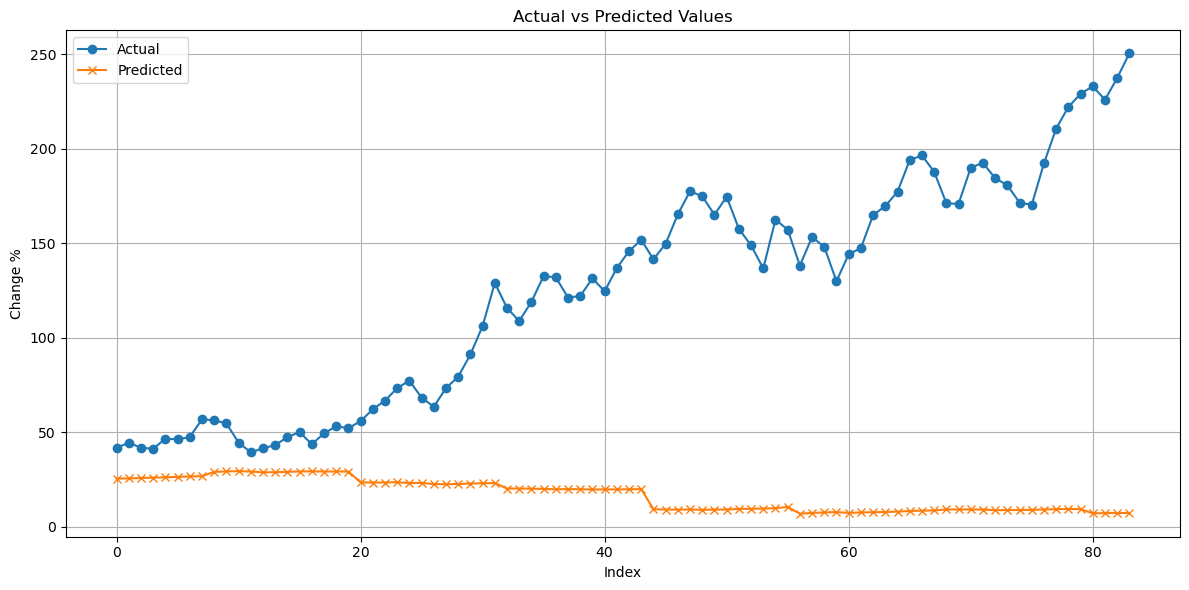

In [13]:
# Fit the OLS (Ordinary Least Squares) multiple linear regression model
model = sm.OLS(y_train, X_train).fit()

# View the model summary
print(model.summary())

vif_data = pd.DataFrame()
vif_data['feature'] = X_train.columns
vif_data['VIF'] = [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]

print(vif_data)

# You can now make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate model performance: Calculate RMSE or R²
rmse = mean_squared_error(y_test, y_pred, squared=False)
r2 = r2_score(y_test, y_pred)

print(f"RMSE: {rmse}")
print(f"R²: {r2}")

plt.figure(figsize=(12, 6))
plt.plot(y_test.values, label='Actual', marker='o')
plt.plot(y_pred.values, label='Predicted', marker='x')
plt.title('Actual vs Predicted Values')
plt.xlabel('Index')
plt.ylabel('Change %')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Ramdom forest 

Random Forest Results:
RMSE: 110.3746
R²: -2.4287
Investment: 0.010
changein_BookEQ: 0.004
CPI: 0.714
FedFunds: 0.011
Year: 0.085
Month: 0.002
PI2A: 0.000
IVC: 0.000
NOA: 0.050
ATO: 0.010
PCM: 0.000
ROE: 0.000
Prof: 0.013
GS2: 0.029
BEME: 0.000
Debt2P: 0.015
Tobin_Q: 0.000
Change_lag1: 0.001
Change_lag2: 0.001
Change_lag3: 0.001
OA: 0.026
C2TAssets: 0.025
E2P: 0.000
FreeCF: 0.000
NOP: 0.000


C:\Users\ns560535\AppData\Local\miniconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


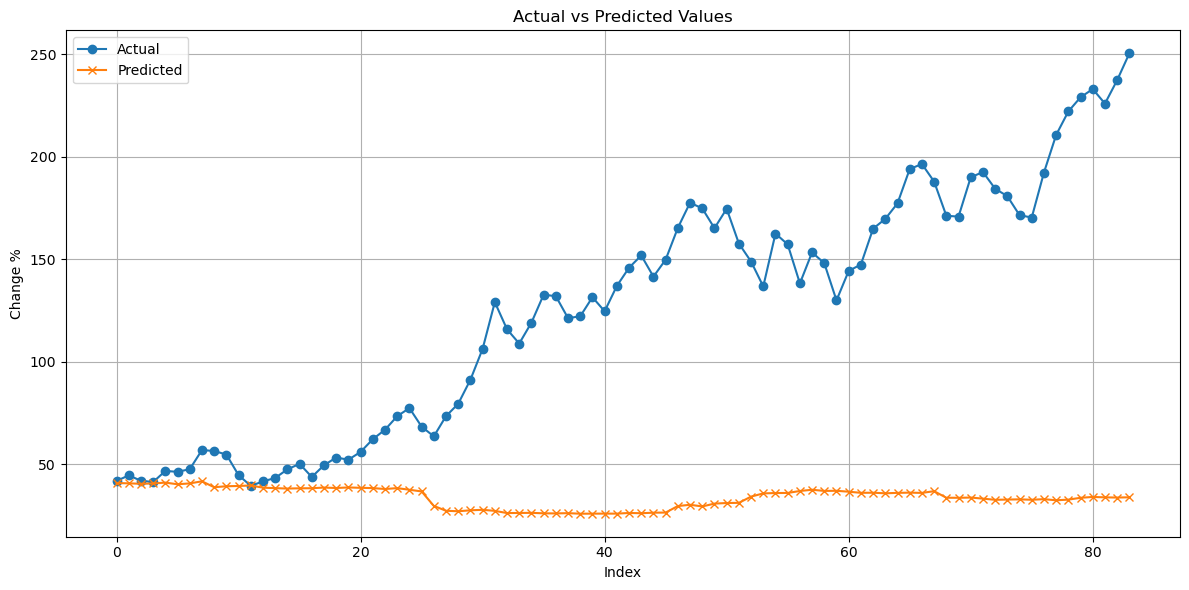

In [15]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# --------------------------
# 2. Instantiate the Model
# --------------------------
# Start with some default hyperparameters.
# You can tune n_estimators, max_depth, min_samples_split, etc. to improve performance.

model = RandomForestRegressor(
    n_estimators=100,    # number of trees in the forest
    max_depth=None,      # trees grow until all leaves are pure or min_samples_split is reached
    random_state=42      # for reproducibility
)

# --------------------------
# 3. Train (Fit) the Model
# --------------------------
model.fit(X_train, y_train)

# --------------------------
# 4. Make Predictions
# --------------------------
y_pred = model.predict(X_test)

# --------------------------
# 5. Evaluate the Model
# --------------------------
rmse = mean_squared_error(y_test, y_pred, squared=False)
r2 = r2_score(y_test, y_pred)

print("Random Forest Results:")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")

# --------------------------
# 6. Inspect Feature Importances (Optional)
# --------------------------
importances = model.feature_importances_
for feat, imp in zip(features, importances):
    print(f"{feat}: {imp:.3f}")

# Graphing the prediction
plt.figure(figsize=(12, 6))
plt.plot(y_test.values, label='Actual', marker='o')
plt.plot(y_pred, label='Predicted', marker='x')
plt.title('Actual vs Predicted Values')
plt.xlabel('Index')
plt.ylabel('Change %')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Deep learning using Feedforward Neural Network

Epoch 1/50
9/9 [==============================] - 1s 18ms/step - loss: 14.8556 - mae: 1.9756 - val_loss: 710.8648 - val_mae: 25.6738
Epoch 2/50
9/9 [==============================] - 0s 4ms/step - loss: 14.0915 - mae: 1.8185 - val_loss: 693.9910 - val_mae: 25.3406
Epoch 3/50
9/9 [==============================] - 0s 4ms/step - loss: 12.7687 - mae: 1.7361 - val_loss: 665.3439 - val_mae: 24.7590
Epoch 4/50
9/9 [==============================] - 0s 4ms/step - loss: 10.2933 - mae: 1.5708 - val_loss: 609.1885 - val_mae: 23.5585
Epoch 5/50
9/9 [==============================] - 0s 4ms/step - loss: 6.4675 - mae: 1.2423 - val_loss: 499.9922 - val_mae: 20.9843
Epoch 6/50
9/9 [==============================] - 0s 4ms/step - loss: 2.7636 - mae: 0.9809 - val_loss: 353.8427 - val_mae: 16.8033
Epoch 7/50
9/9 [==============================] - 0s 4ms/step - loss: 1.1908 - mae: 0.6776 - val_loss: 320.0578 - val_mae: 15.6489
Epoch 8/50
9/9 [==============================] - 0s 3ms/step - loss: 0.6959 -

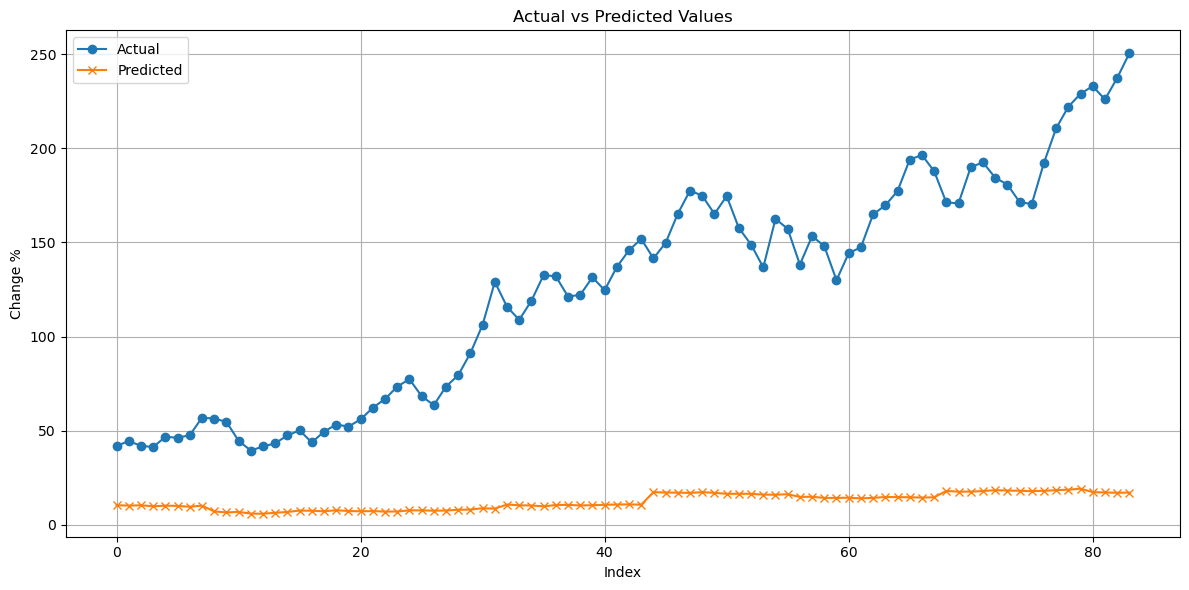

In [17]:
# Build the Feedforward Neural Network (FNN)
model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1)  # Output layer for regression (predicting a continuous value)
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Train the Model with Early Stopping
#early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(X_train, y_train, 
                    validation_split=0.2, 
                    epochs=50, 
                    batch_size=32, 
                    #callbacks=[early_stop], #Enable this if using early stop
                    verbose=1)

# Evaluate the Model on Test Data
test_loss, test_mae = model.evaluate(X_test, y_test)
print("Test Loss (MSE):", test_loss)
print("Test MAE:", test_mae)

# Make Predictions and Calculate RMSE and R²
y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2   = r2_score(y_test, y_pred)

print("Test RMSE:", rmse)
print("Test R²:", r2)

plt.figure(figsize=(12, 6))
plt.plot(y_test.values, label='Actual', marker='o')
plt.plot(y_pred, label='Predicted', marker='x')
plt.title('Actual vs Predicted Values')
plt.xlabel('Index')
plt.ylabel('Change %')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()